# Import Libraries

In [7]:
import holidays
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import yfinance as yf

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from statsmodels.tsa.stattools import adfuller, kpss

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.stattools import grangercausalitytests

---
# **Part 1 - KNN**
---
Importing & Exploring  Dataset

In [ ]:
df = pd.read_csv("airline_passenger_satisfaction.csv")
discription = pd.read_csv("airlines_data_dictionary.csv")

print("Dimensions of datasets: ",df.shape, discription.shape)
print("\nDatasets Overview:\n")

df.columns = df.columns.str.strip()
display(df.head(), discription.head(24))

Dimensions of datasets:  (129880, 24) (24, 2)

Datasets Overview:



,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0.0,4,...,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0.0,2,...,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1.0,3,...,3,4,4,5,4,3,3,3,3,Satisfied


,Field,Description
0,ID,Unique passenger identifier
1,Gender,Gender of the passenger (Female/Male)
2,Age,Age of the passenger
3,Customer Type,Type of airline customer (First-time/Returning)
4,Type of Travel,Purpose of the flight (Business/Personal)
5,Class,Travel class in the airplane for the passenger...
6,Flight Distance,Flight distance in miles
7,Departure Delay,Flight departure delay in minutes
8,Arrival Delay,Flight arrival delay in minutes
9,Departure and Arrival Time Convenience,Satisfaction level with the convenience of the...


In [ ]:
# Checking for NaN values and Replacing with attribute's median value.
print(df.isnull().sum())


ID                                          0
Gender                                      0
Age                                         0
Customer Type                               0
Type of Travel                              0
Class                                       0
Flight Distance                             0
Departure Delay                             0
Arrival Delay                             393
Departure and Arrival Time Convenience      0
Ease of Online Booking                      0
Check-in Service                            0
Online Boarding                             0
Gate Location                               0
On-board Service                            0
Seat Comfort                                0
Leg Room Service                            0
Cleanliness                                 0
Food and Drink                              0
In-flight Service                           0
In-flight Wifi Service                      0
In-flight Entertainment           

In [ ]:
df['Arrival Delay'] = df['Arrival Delay'].fillna(df['Arrival Delay'].median())
print(df.isnull().sum())

ID                                        0
Gender                                    0
Age                                       0
Customer Type                             0
Type of Travel                            0
Class                                     0
Flight Distance                           0
Departure Delay                           0
Arrival Delay                             0
Departure and Arrival Time Convenience    0
Ease of Online Booking                    0
Check-in Service                          0
Online Boarding                           0
Gate Location                             0
On-board Service                          0
Seat Comfort                              0
Leg Room Service                          0
Cleanliness                               0
Food and Drink                            0
In-flight Service                         0
In-flight Wifi Service                    0
In-flight Entertainment                   0
Baggage Handling                

1.Histograms & Barplots for numeric & categorical values

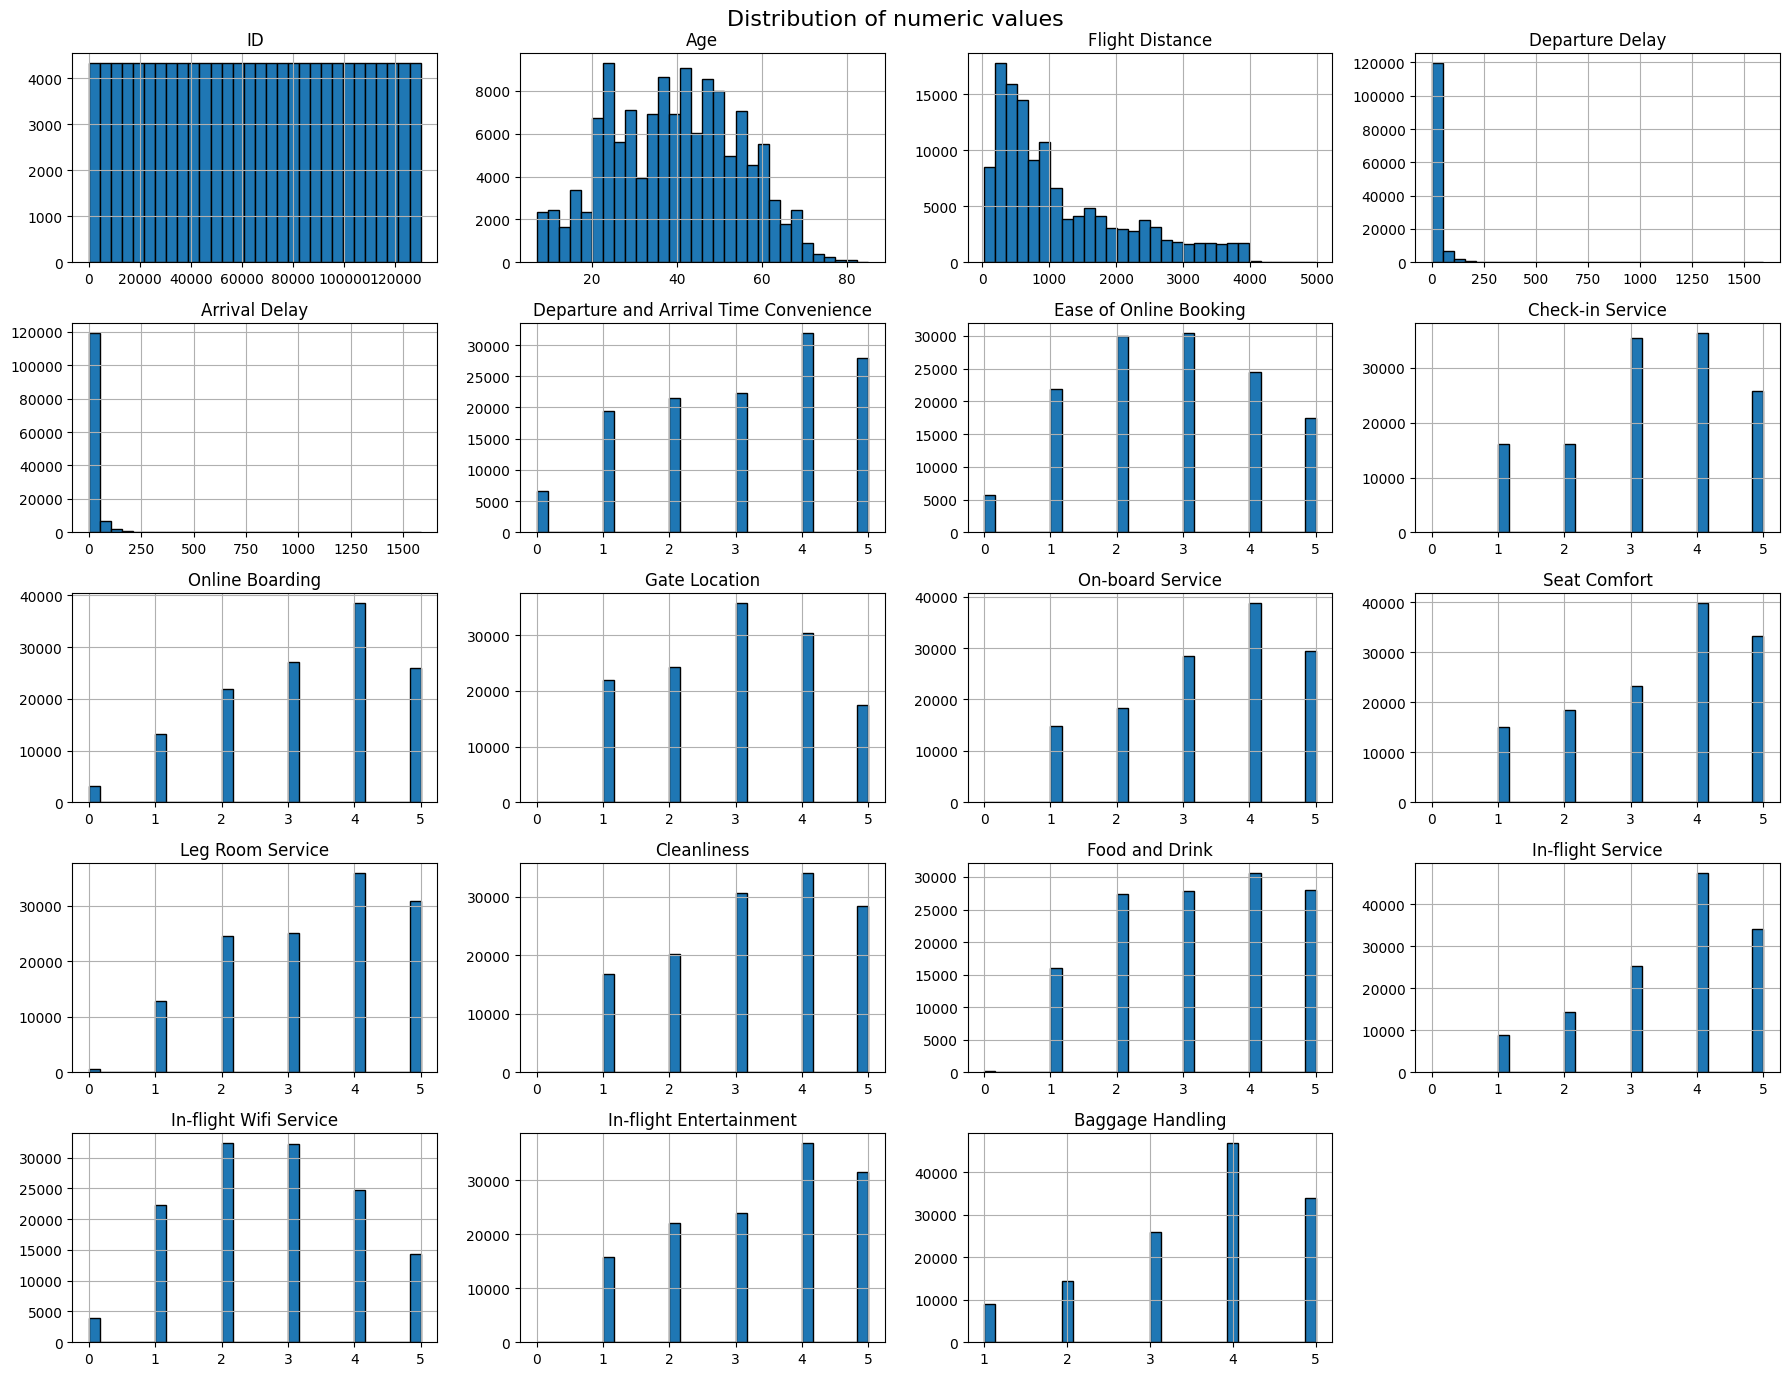

In [ ]:
#Dropping target value 'Satisfaction' and choosing only numeric values for Histogram
numeric_cols = df.drop(columns=["Satisfaction"])
numeric_cols = numeric_cols.select_dtypes(include=np.number).columns.tolist()

df[numeric_cols].hist(bins=30,figsize=(18, 14),edgecolor='black')

plt.suptitle('Distribution of numeric values', fontsize=16)
plt.tight_layout()
plt.show()

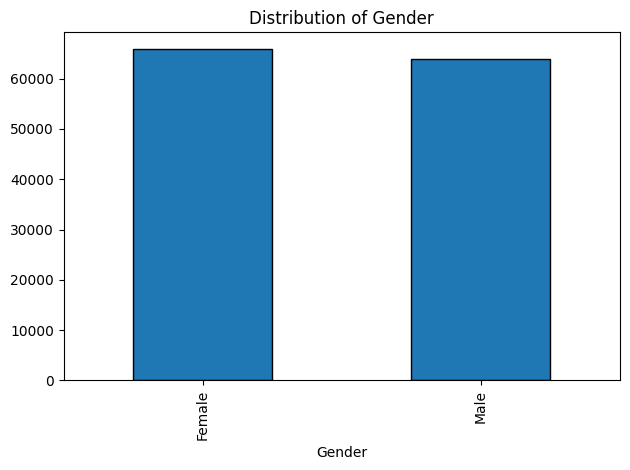

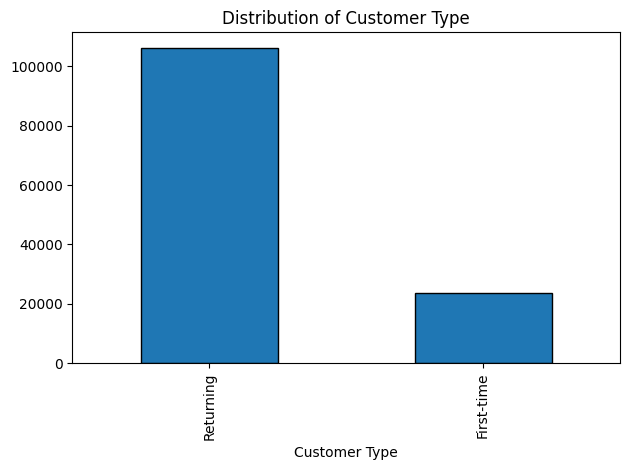

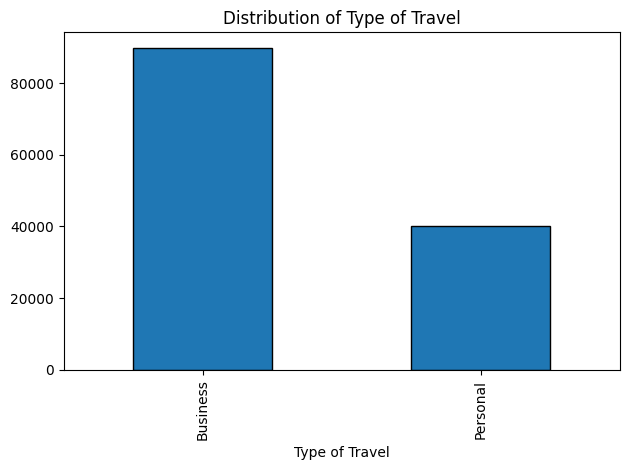

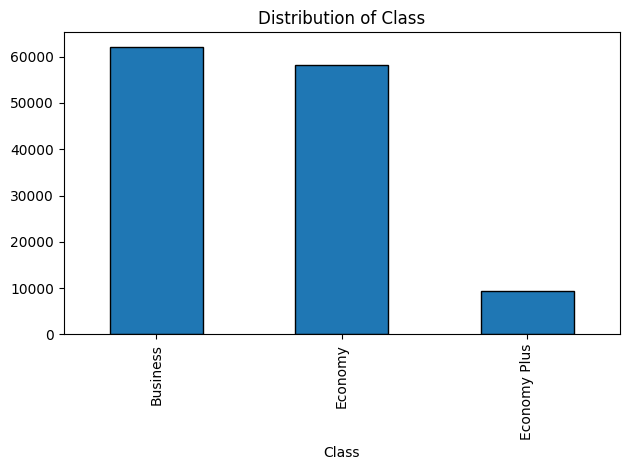

In [ ]:
#Dropping target value 'Satisfaction' and choosing only categorical values for Barplot
categ_cols = df.drop(columns=["Satisfaction"])
categ_cols = categ_cols.select_dtypes(include=['category', 'object']).columns.tolist()

#Plot for every categorical attribute
for col in categ_cols:

  df[col].value_counts().plot(kind='bar', edgecolor='black')
  plt.title(f'Distribution of {col}')
  plt.tight_layout()
  plt.show()

**Based on Barplots we can assume the following info about the classes of attributes**
- Gender : The distribution between two genders are equally balanced.
- Customer Type: Imbalanced distribution, as we have most of the customers as   "Returning", compared to the "First-Time" customers.
- Type of Travel : Imbalanced distribution, because most of the type of travels are "Business", with not so many "Personal" travels.
- Class: "Businees" & "Economy" classes, seem to be equally distributed. But the amount of "Economy Plus" has the least preferance compared to the other two

2. One-Hote Encoding for nominal attributes like : Gender, Customer Type, Class, Type of Travel

In [ ]:
#Encoding nominal attributes
nominal_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class']

encoder = OneHotEncoder(sparse_output=False)

encoded_data = encoder.fit_transform(df[nominal_cols])

#Creating new dataFrame
encoded_df = pd.DataFrame(encoded_data, columns=encoder.get_feature_names_out(nominal_cols),index=df.index)

# Replacing original attributes with encoded
df = df.drop(columns=nominal_cols)
df = pd.concat([df, encoded_df], axis=1)

df.head()

,ID,Age,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,Ease of Online Booking,Check-in Service,Online Boarding,Gate Location,...,Satisfaction,Gender_Female,Gender_Male,Customer Type_First-time,Customer Type_Returning,Type of Travel_Business,Type of Travel_Personal,Class_Business,Class_Economy,Class_Economy Plus
0,1,48,821,2,5.0,3,3,4,3,3,...,Neutral or Dissatisfied,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
1,2,35,821,26,39.0,2,2,3,5,2,...,Satisfied,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
2,3,41,853,0,0.0,4,4,4,5,4,...,Satisfied,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
3,4,50,1905,0,0.0,2,2,3,4,2,...,Satisfied,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
4,5,49,3470,0,1.0,3,3,3,5,3,...,Satisfied,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0


3. Splitting Train-Test sets

In [ ]:
# Train - Test split
X = df.drop(columns=["Satisfaction"]).to_numpy()
y = df["Satisfaction"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=0)

print("Train:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)



Train: (90916, 28) (90916,)
Test: (38964, 28) (38964,)


4. Normalization of numerical values

In [ ]:
#We already have numerical columns, since cell 1

# Locating numeric columns index
numeric_index = []
num_cols = df.drop(columns=['Satisfaction']).columns

for col in numeric_cols:
  numeric_index.append(num_cols.get_loc(col))


# Normalization process for numeric, based on indexes
scaler = StandardScaler()

X_train[:, numeric_index] = scaler.fit_transform(X_train[:, numeric_index])

X_test[:, numeric_index] = scaler.transform(X_test[:, numeric_index])

df.head()

,ID,Age,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,Ease of Online Booking,Check-in Service,Online Boarding,Gate Location,...,Satisfaction,Gender_Female,Gender_Male,Customer Type_First-time,Customer Type_Returning,Type of Travel_Business,Type of Travel_Personal,Class_Business,Class_Economy,Class_Economy Plus
0,1,48,821,2,5.0,3,3,4,3,3,...,Neutral or Dissatisfied,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
1,2,35,821,26,39.0,2,2,3,5,2,...,Satisfied,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
2,3,41,853,0,0.0,4,4,4,5,4,...,Satisfied,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
3,4,50,1905,0,0.0,2,2,3,4,2,...,Satisfied,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
4,5,49,3470,0,1.0,3,3,3,5,3,...,Satisfied,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0


**We normalize only numeric columns, not the One-Hot encoded columns, because they have already 0/1 values**

In [ ]:
# Checking square_root(N), because we always need  k = odd number

N = len(df)
square_N = int(N ** 0.5)

if (square_N % 2 == 0):
  square_N -= 1
print(square_N)

359


5. Training and Evaluation Phase

In [ ]:
# Training with Uniform KNN
k_values = [3, 5, 15, 51, 151, square_N]

results_uni = []

for k in k_values:

        knn = KNeighborsClassifier(n_neighbors=k, weights='uniform', metric='euclidean')

        knn.fit(X_train, y_train)

        train_pred = knn.predict(X_train)
        test_pred = knn.predict(X_test)

        train_acc = accuracy_score(y_train, train_pred)
        test_acc = accuracy_score(y_test, test_pred)

#Importing result into a table
        results_uni.append({
            'k': k,
            'weights': 'uniform',
            'Train Accuracy': train_acc,
            'Test Accuracy': test_acc
        })

results_df1 = pd.DataFrame(results_uni)

print(results_df1.round(4))

     k  weights  Train Accuracy  Test Accuracy
0    3  uniform          0.9590         0.9256
1    5  uniform          0.9500         0.9278
2   15  uniform          0.9362         0.9289
3   51  uniform          0.9253         0.9233
4  151  uniform          0.9143         0.9136
5  359  uniform          0.9057         0.9058


**We observe that small 'k' sizes, produce better model performance.
This means that, k = 15 has the best performance for Uniform KNN.**

In [ ]:
# Training with Weighted KNN
k_values = [3, 5, 15, 51, 151, square_N]

results_dist = []

for k in k_values:

        knn = KNeighborsClassifier(n_neighbors=k, weights='distance', metric='euclidean')

        knn.fit(X_train, y_train)

        train_pred = knn.predict(X_train)
        test_pred = knn.predict(X_test)

        train_acc = accuracy_score(y_train, train_pred)
        test_acc = accuracy_score(y_test, test_pred)

#Importing result into a table
        results_dist.append({
            'weights': 'distance',
            'Train Accuracy': train_acc,
            'Test Accuracy': test_acc
        })

results_df2 = pd.DataFrame(results_dist)

print(results_df2.round(4))

    weights  Train Accuracy  Test Accuracy
0  distance             1.0         0.9256
1  distance             1.0         0.9278
2  distance             1.0         0.9291
3  distance             1.0         0.9242
4  distance             1.0         0.9147
5  distance             1.0         0.9072


**We observe that small 'k' sizes, produce better model performance. This means that, k = 15 has the best performance for Weighted KNN.**

In [ ]:
KNN_result = pd.concat([results_df1, results_df2], axis =1)
display(KNN_result)

,k,weights,Train Accuracy,Test Accuracy,weights,Train Accuracy,Test Accuracy
0,3,uniform,0.959039,0.925624,distance,1.0,0.925624
1,5,uniform,0.950009,0.927805,distance,1.0,0.927779
2,15,uniform,0.936216,0.928909,distance,1.0,0.929114
3,51,uniform,0.925338,0.923288,distance,1.0,0.924212
4,151,uniform,0.914251,0.913561,distance,1.0,0.914690
5,359,uniform,0.905748,0.905836,distance,1.0,0.907196


---
# **Part 2 - Time Series**
---

# Download Financial Data

Download 10 years of USD Index. Columns Volume, Dividends and Stock Splits are not required, since they are constant and equal to 0.0

In [3]:
ticker_symbol = 'DX-Y.NYB'

ticker = yf.Ticker(ticker_symbol)
df = ticker.history(period='10y').drop(columns=['Volume', 'Dividends', 'Stock Splits']).reset_index(drop=False)
df

,Date,Open,High,Low,Close
0,2016-10-31 00:00:00-04:00,98.320000,98.699997,98.290001,98.449997
1,2016-11-01 00:00:00-04:00,98.389999,98.480003,97.639999,97.699997
2,2016-11-02 00:00:00-04:00,97.750000,97.800003,97.180000,97.400002
3,2016-11-03 00:00:00-04:00,97.379997,97.459999,97.040001,97.160004
4,2016-11-04 00:00:00-04:00,97.160004,97.349998,96.889999,97.070000
...,...,...,...,...,...
2509,2026-10-23 00:00:00-04:00,101.570000,101.849998,101.489998,101.809998
2510,2026-10-26 00:00:00-04:00,101.779999,102.059998,101.580002,101.959999
2511,2026-10-27 00:00:00-04:00,102.029999,102.400002,101.989998,102.320000
2512,2026-10-28 00:00:00-04:00,102.370003,102.489998,102.050003,102.190002


1. Descriptive Analysis

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Open,2514.0,98.799560,4.971375,88.570000,95.172499,98.424999,102.457499,114.190002
High,2514.0,99.100453,5.019014,89.000000,95.529999,98.709999,102.757502,114.779999
Low,2514.0,98.509756,4.915195,88.250000,94.992498,98.190002,102.070000,113.330002
Close,2514.0,98.809578,4.972906,88.589996,95.172499,98.435001,102.455000,114.110001


**Attributes Description:**
- (O)pen: Opening price for that day -> Mean price: 98.79 & St. Deviation: 4.9
- (H)igh: The highest price recorded during the day -> Mean price: 99.09 &Deviation: 5.01
- (Low): Lowest price recorded that day -> Mean price: 98.5 & Deviation: 4.91
- (C)lose: Closing price for that day -> Mean price: 98.8 & Deviation: 4.97
- (V)olume: Trading volume, i.e. Number of traded units -> Mean price: 98.7 & Deviation: 4.9

# Construct Line Plot of HLC Data

In [5]:
fig = px.line(df, x='Date', y=['High', 'Close', 'Low'], title='USD Price Index from 2016 to 2026')
fig.show()

**2.Based on the chart, this time series is non static:**
- Trends: The series in not moving around a constant horizontal average
- Seasonality: There are many waves-patterns that are not stable

3. ADF & KPSS tests for 'Close' attribute

In [11]:
close = df['Close']

# ADF Test
adf_result = adfuller(close)

# KPSS Test
kpss_result = kpss(close)

print("Test results:")
print((f"ADF Test: {adf_result[1]}"))
print((f"KPSS Test: {kpss_result[1]}"))

Test results:
ADF Test: 0.3360894452759847
KPSS Test: 0.01


/tmp/ipykernel_1157/1691494013.py:4: FutureWarning:

adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.

/tmp/ipykernel_1157/1691494013.py:7: InterpolationWarning:

The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.

/tmp/ipykernel_1157/1691494013.py:7: FutureWarning:

kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current 

In [16]:
if adf_result[1] < 0.05 and kpss_result[1] >= 0.05:
    print("The series is not stationary.")
elif adf_result[1] >= 0.05 and kpss_result[1] < 0.05:
    print("The series is not stationary.")
else:
    print("Series need more investigation.")

The series is not stationary.


**According to the test, we can assume that the serie is non-static**

# Train-Test Split

4. Test set should start 1 time step after the end of train set.

In [17]:
train_size = 0.7
history_size = 30

num_train_samples = int(df.shape[0]*train_size)
train_df = df.iloc[:num_train_samples]
test_df = df.iloc[num_train_samples - history_size:]

train_df.shape, test_df.shape

((1759, 5), (785, 5))

# Construct Timeframes

*   x = <x[0], x[1], x[2], ... x[H-1]>
*   y = x[H]

where x is (Open(t), High(t), Low(t), Close(t))

**Important: Past target must be included in x to achieve good accuracy**

In [18]:
def construct_timeframes(df, H):
    inputs = df.drop(columns=['Date']).to_numpy(dtype=np.float64)
    x = np.array([inputs[i-H: i].flatten() for i in range(H, df.shape[0])])
    y = df['Close'].to_numpy(dtype=np.float64)[H:]
    return x, y

# Verify Timeframes

In [19]:
train_df.head(5)

,Date,Open,High,Low,Close
0,2016-10-31 00:00:00-04:00,98.320000,98.699997,98.290001,98.449997
1,2016-11-01 00:00:00-04:00,98.389999,98.480003,97.639999,97.699997
2,2016-11-02 00:00:00-04:00,97.750000,97.800003,97.180000,97.400002
3,2016-11-03 00:00:00-04:00,97.379997,97.459999,97.040001,97.160004
4,2016-11-04 00:00:00-04:00,97.160004,97.349998,96.889999,97.070000


In [20]:
x_train, y_train = construct_timeframes(train_df, H=4)
print('x:', x_train[0],'\ny:', y_train[0])

x: [98.31999969 98.69999695 98.29000092 98.44999695 98.38999939 98.48000336
 97.63999939 97.69999695 97.75       97.80000305 97.18000031 97.40000153
 97.37999725 97.45999908 97.04000092 97.16000366] 
y: 97.06999969482422


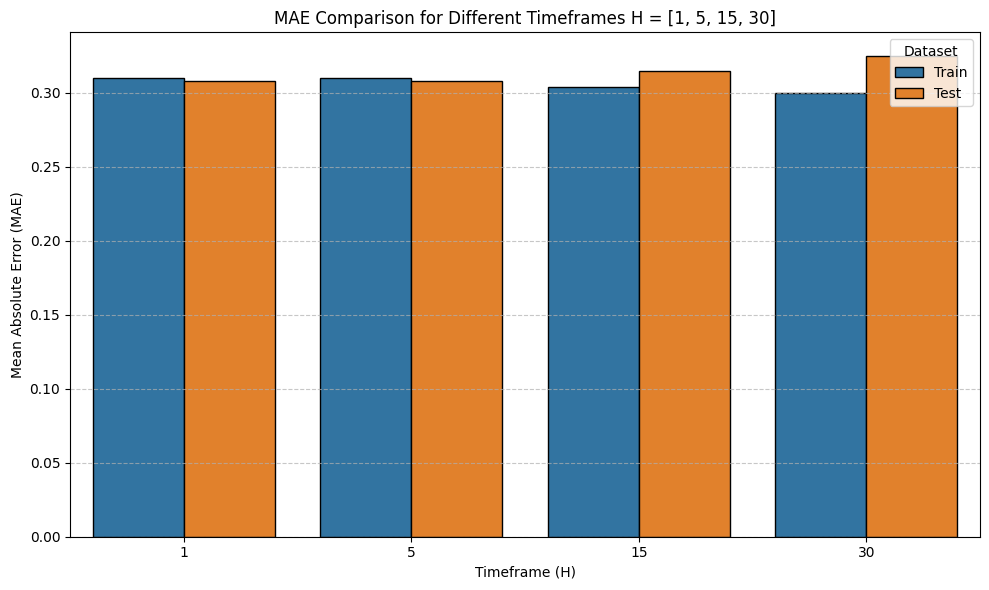

In [41]:
# Defining the H values
h_values = [1, 5, 15, 30]

results_list = []

for H in h_values:
    # Creating Train-Test for each H
    x_train, y_train = construct_timeframes(train_df, H)
    x_test, y_test = construct_timeframes(test_df, H)

    # Training linear model for each H
    model = LinearRegression()
    model.fit(x_train, y_train)

    # Predicting and calculating MAE for each H
    train_pred = model.predict(x_train)
    test_pred = model.predict(x_test)

    train_mae = mean_absolute_error(y_train, train_pred)
    test_mae = mean_absolute_error(y_test, test_pred)

    # Store results
    results_list.append({'H': H, 'Dataset': 'Train', 'MAE': train_mae})
    results_list.append({'H': H, 'Dataset': 'Test', 'MAE': test_mae})

# Converting results to DataFrame for visualization
results = pd.DataFrame(results_list)

# Visualization
plt.figure(figsize=(10, 6))
sns.barplot(data=results, x='H', y='MAE', hue='Dataset', edgecolor='black')
plt.title('MAE Comparison for Different Timeframes H = [1, 5, 15, 30]')
plt.xlabel('Timeframe (H)')
plt.ylabel('Mean Absolute Error (MAE)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


**Base on the Barplot we understand that bigger Timeframes lead to error increasement on the Test set**

# Fit Linear Regression Model

6. Setting H = 30

In [21]:
x_train, y_train = construct_timeframes(train_df, history_size)
x_test, y_test = construct_timeframes(test_df, history_size)

x_train.shape, y_train.shape, x_test.shape, y_test.shape

((1729, 120), (1729,), (755, 120), (755,))

<Axes: title={'center': 'Train-Test MAE of Linear Regression with H=30'}, xlabel='Dataset', ylabel='MAE'>

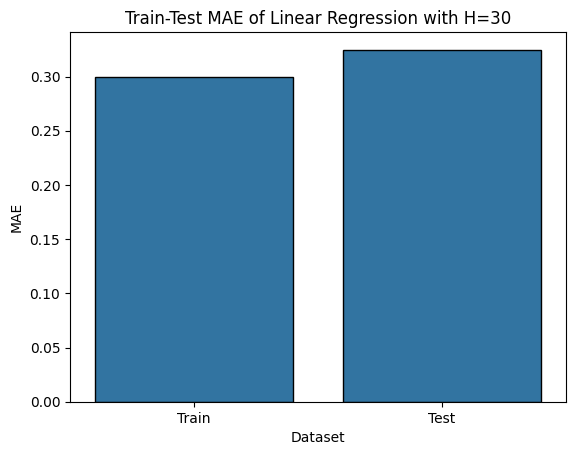

In [22]:
model = LinearRegression()
model.fit(x_train, y_train)

y_pred = model.predict(x_train)
train_mae = mean_absolute_error(y_true=y_train, y_pred=y_pred)
y_pred = model.predict(x_test)
test_mae = mean_absolute_error(y_true=y_test, y_pred=y_pred)

metrics_df = pd.DataFrame({'Dataset': ['Train', 'Test'], 'MAE': [train_mae, test_mae]})
ax = sns.barplot(metrics_df, x='Dataset', y='MAE', edgecolor='black')
ax.set_title('Train-Test MAE of Linear Regression with H=30')
ax

**Based on the barplot, the MAE for the train set is approximately 0.30, while for the test set it is slightly higher, at approximately 0.32. This small difference indicates that the model does not overfit and generalizes well to new data.**

# Visualize Predictions

In [42]:
train_dates = train_df['Date'].iloc[history_size:]
test_dates = test_df['Date'].iloc[history_size:]

# Create figure
fig = go.Figure()

# Training data (last history_size samples only)
fig.add_trace(go.Scatter(
    x=train_dates.iloc[-history_size:],
    y=np.ravel(y_train)[-history_size:],
    mode='lines',
    name='Train',
    line=dict(color='royalblue', width=2)
))

# Test actual values
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_test),
    mode='lines',
    name='Test (Actual)',
    line=dict(color='royalblue', width=2, dash='dash')
))

# Vertical dashed line separating train/test
fig.add_shape(
    type='line',
    x0=test_dates.iloc[0],
    x1=test_dates.iloc[0],
    y0=0,
    y1=1,
    xref='x',
    yref='paper',
    line=dict(color='black', width=2, dash='dash')
)

# Prediction line for test set
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_pred),
    mode='lines',
    name='Test (Predicted)',
    line=dict(color='#E63946', width=2.5)
))

# Layout
fig.update_layout(
    title='USD Price Index — Close Price Prediction',
    xaxis_title='Date',
    yaxis_title='Price ($)',
    template='plotly_white',
    legend=dict(x=0.01, y=0.99),
    hovermode='x unified'
)

fig.show()

**Based on observation the predicted line, mirrors the actual line and the model has not learned the sequential pattern.**

## 7. Apply Log Returns Transformation

In [33]:
vars = ['Open', 'High', 'Low', 'Close']
df_logr = df.copy()
df_logr[vars] = np.log(df_logr[vars]/df_logr[vars].shift(1))
df_logr

,Date,Open,High,Low,Close,Month,DayOfWeek,IsHoliday
0,2016-10-31 00:00:00-04:00,NaN,NaN,NaN,NaN,10,0,1
1,2016-11-01 00:00:00-04:00,0.000712,-0.002231,-0.006635,-0.007647,11,1,0
2,2016-11-02 00:00:00-04:00,-0.006526,-0.006929,-0.004722,-0.003075,11,2,0
3,2016-11-03 00:00:00-04:00,-0.003792,-0.003483,-0.001442,-0.002467,11,3,0
4,2016-11-04 00:00:00-04:00,-0.002262,-0.001129,-0.001547,-0.000927,11,4,0
...,...,...,...,...,...,...,...,...
2509,2026-10-23 00:00:00-04:00,-0.001377,-0.000294,0.000394,0.001966,10,4,0
2510,2026-10-26 00:00:00-04:00,0.002065,0.002060,0.000886,0.001472,10,0,0
2511,2026-10-27 00:00:00-04:00,0.002453,0.003326,0.004028,0.003525,10,1,0
2512,2026-10-28 00:00:00-04:00,0.003327,0.000878,0.000588,-0.001271,10,2,0


# Convert Log Returns to Absolute Price

$lr_{t+1} = \ln(\frac{y_{t+1}}{y_{t}})$

$y_{t+1} = y_t * e^{lr_{t+1}}$

Inevitably, the first sample will be lost, as its log-return transformation cannot be defined (x[-1] does not exist).

In [24]:
def log_returns_to_absolute_prices(prices, log_returns):
    return prices * np.exp(log_returns)

In [34]:
valid_df = pd.DataFrame({
    'Date': df['Date'].iloc[: 6],
    'Close': df['Close'].iloc[: 6],
    'CLose-Log-Returns': df_logr['Close'].iloc[: 6]
})
valid_df

,Date,Close,CLose-Log-Returns
0,2016-10-31 00:00:00-04:00,98.449997,NaN
1,2016-11-01 00:00:00-04:00,97.699997,-0.007647
2,2016-11-02 00:00:00-04:00,97.400002,-0.003075
3,2016-11-03 00:00:00-04:00,97.160004,-0.002467
4,2016-11-04 00:00:00-04:00,97.070000,-0.000927
5,2016-11-07 00:00:00-05:00,97.779999,0.007288


In [35]:
log_returns_to_absolute_prices(
    prices=valid_df['Close'].iloc[: -1].to_numpy(),
    log_returns=valid_df['CLose-Log-Returns'].iloc[1:].to_numpy()
)

array([97.69999695, 97.40000153, 97.16000366, 97.06999969, 97.77999878])

# Check Whether High can Predict Close

Variables that can estimate the target variable are considered beneficial.

In [36]:
data = train_df[['Close', 'Open']]

# Computing log-returns (converting to stationary series).
data = np.log(data/data.shift(1)).dropna()

# Test up to history_size lags
results = grangercausalitytests(data[['Close', 'Open']], maxlag=history_size)

# Extract p-values
p_values = {
    lag: results[lag][0]['ssr_ftest'][1]
    for lag in range(1, history_size + 1)
}
results_df = pd.DataFrame({'Lag (H)': list(p_values.keys()), 'P-value': list(p_values.values())})
results_df['Significant'] = results_df['P-value'] < 0.05
results_df

,Lag (H),P-value,Significant
0,1,0.191609,False
1,2,0.820257,False
2,3,0.525268,False
3,4,0.785338,False
4,5,0.025691,True
5,6,0.636667,False
6,7,0.725205,False
7,8,0.392926,False
8,9,0.278278,False
9,10,0.493648,False


# Extracting Temporal Features

In [32]:
# Calendar features
df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek  # Monday=0, Sunday=6

# US & NYSE holidays
us_holidays = holidays.country_holidays('US')
nyse_holidays = holidays.financial_holidays('NYSE')

# Global events
global_events = {
    'NewYearsDay': (1, 1),
    'ValentinesDay': (2, 14),
    'WomensDay': (3, 8),
    'AprilFools': (4, 1),
    'EarthDay': (4, 22),
    'LabourDay': (5, 1),
    'EnvironmentDay': (6, 5),
    'Halloween': (10, 31),
    'ChristmasEve': (12, 24),
    'ChristmasDay': (12, 25),
    'BoxingDay': (12, 26),
    'NewYearsEve': (12, 31),
}

event_dates = set(global_events.values())

# Combine US holidays, NYSE holidays, and global events
df['IsHoliday'] = df['Date'].dt.date.map(
    lambda d: int(
        d in us_holidays
        or d in nyse_holidays
        or (d.month, d.day) in event_dates
    )
)

df

,Date,Open,High,Low,Close,Month,DayOfWeek,IsHoliday
0,2016-10-31 00:00:00-04:00,98.320000,98.699997,98.290001,98.449997,10,0,1
1,2016-11-01 00:00:00-04:00,98.389999,98.480003,97.639999,97.699997,11,1,0
2,2016-11-02 00:00:00-04:00,97.750000,97.800003,97.180000,97.400002,11,2,0
3,2016-11-03 00:00:00-04:00,97.379997,97.459999,97.040001,97.160004,11,3,0
4,2016-11-04 00:00:00-04:00,97.160004,97.349998,96.889999,97.070000,11,4,0
...,...,...,...,...,...,...,...,...
2509,2026-10-23 00:00:00-04:00,101.570000,101.849998,101.489998,101.809998,10,4,0
2510,2026-10-26 00:00:00-04:00,101.779999,102.059998,101.580002,101.959999,10,0,0
2511,2026-10-27 00:00:00-04:00,102.029999,102.400002,101.989998,102.320000,10,1,0
2512,2026-10-28 00:00:00-04:00,102.370003,102.489998,102.050003,102.190002,10,2,0


In [29]:
df['IsHoliday'].value_counts()

,count
IsHoliday,
0,2422
1,92
